In [23]:
import os
import random
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing import image
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

=== Class Distribution ===
           Train Count  Test Count
buildings         2191         437
forest            2271         474
glacier           2404         553
mountain          2512         525
sea               2274         510
street            2382         501


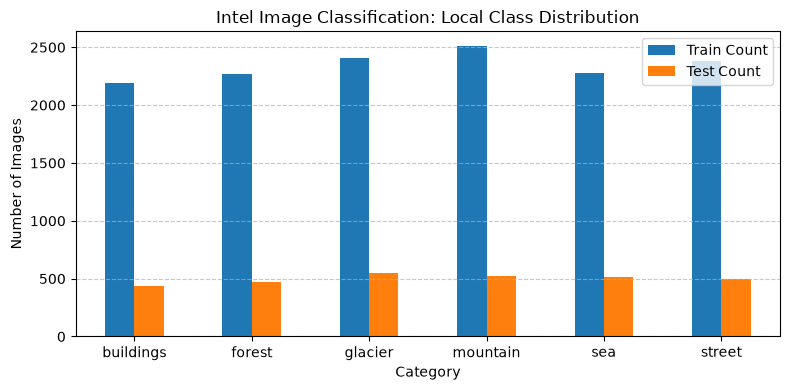

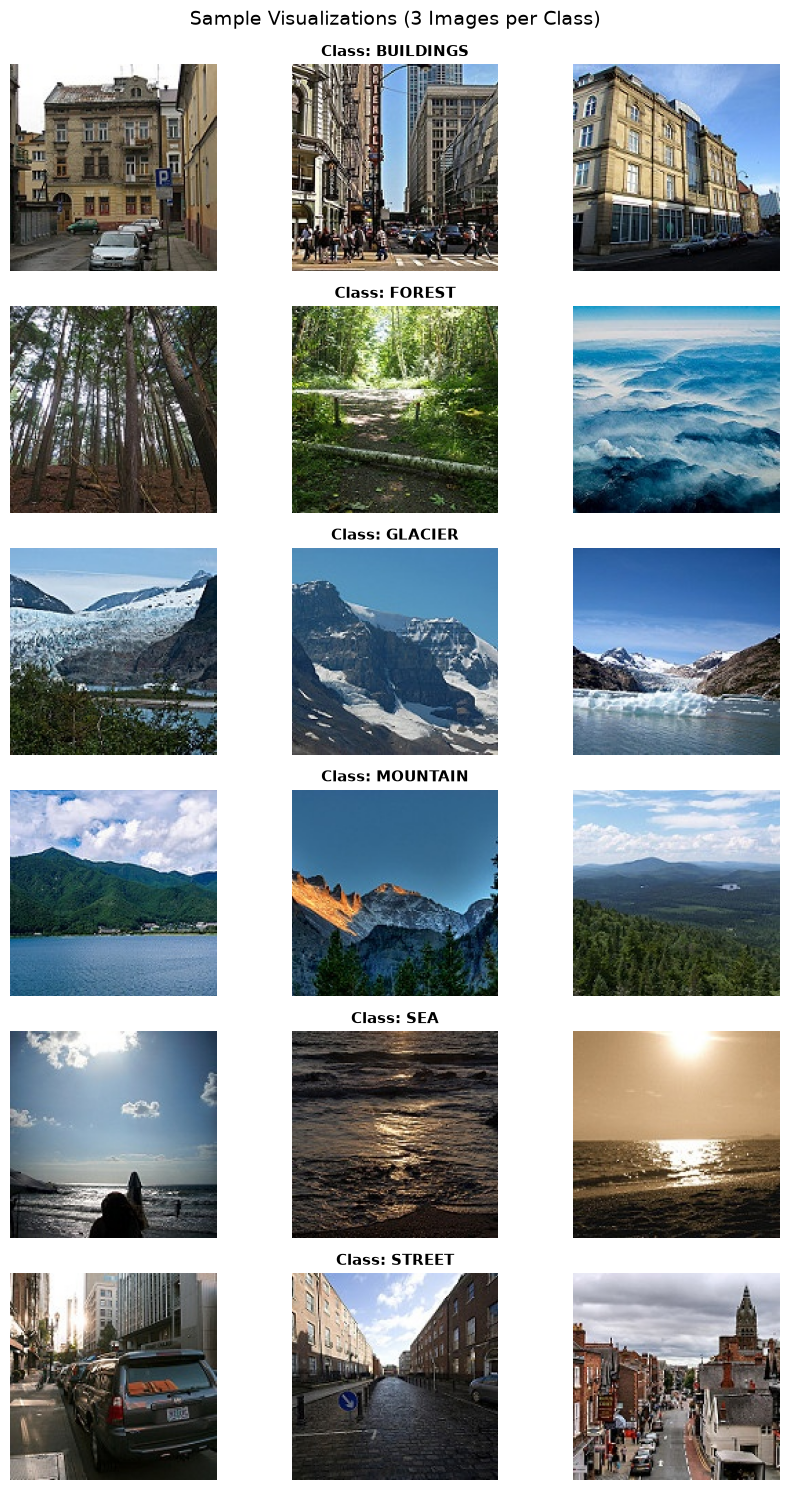

In [24]:
# 1. Point directly to your local directory paths
# Adjust 'seg_train' / 'seg_test' if your local folder structure differs slightly
train_dir = "seg_train" 
test_dir = "seg_test"

# 2. Exploratory Data Analysis (EDA)
classes = sorted(os.listdir(train_dir))
train_counts = {c: len(os.listdir(os.path.join(train_dir, c))) for c in classes}
test_counts = {c: len(os.listdir(os.path.join(test_dir, c))) for c in classes}

eda_df = pd.DataFrame({'Train Count': train_counts, 'Test Count': test_counts})
print("=== Class Distribution ===")
print(eda_df)

# Plot Class Distribution
fig, ax = plt.subplots(figsize=(8, 4))
eda_df.plot(kind='bar', ax=ax)
plt.title('Intel Image Classification: Local Class Distribution')
plt.xlabel('Category')
plt.ylabel('Number of Images')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 3. Display 3 Images per Class
fig, axes = plt.subplots(len(classes), 3, figsize=(9, 15))
fig.suptitle("Sample Visualizations (3 Images per Class)", fontsize=14, y=0.99)

random.seed(42)

for row_idx, cls_name in enumerate(classes):
    cls_path = os.path.join(train_dir, cls_name)
    image_files = os.listdir(cls_path)
    selected_imgs = random.sample(image_files, 3)
    
    for col_idx, img_name in enumerate(selected_imgs):
        img_path = os.path.join(cls_path, img_name)
        img = Image.open(img_path)
        
        ax = axes[row_idx, col_idx]
        ax.imshow(img)
        ax.axis('off')
        if col_idx == 1:
            ax.set_title(f"Class: {cls_name.upper()}", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

In [25]:
# 1. Load Data from Local Directories
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    "seg_train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "seg_test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

# Rescale pixel values from [0, 255] to [0, 1]
normalization_layer = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

# 2. Design the CNN Architecture
model = models.Sequential([
    # Input Layer
    layers.Input(shape=(150, 150, 3)),
    
    # --- 3 CONVOLUTIONAL LAYERS ---
    # Conv Layer 1
    layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Conv Layer 2
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Conv Layer 3
    layers.Conv2D(128, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Flatten spatial features into a 1D vector
    layers.Flatten(),
    
    # --- 3 DENSE LAYERS ---
    # Dense Layer 1 (Hidden)
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5), # Dropout for regularization
    
    # Dense Layer 2 (Hidden)
    layers.Dense(256, activation='relu'),
    
    # Dense Layer 3 (Output Layer for 6 classes)
    layers.Dense(6, activation='softmax')
])

# 3. Compile the Model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Display model summary structure
model.summary()

# 4. Train the Model
epochs = 15
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Found 14034 files belonging to 6 classes.
Found 3000 files belonging to 6 classes.


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 512)            │    21,234,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,460,294 (81.86 MB)

 Trainable params: 21,460,294 (81.86 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


439/439 ━━━━━━━━━━━━━━━━━━━━ 138s 312ms/step - accuracy: 0.6063 - loss: 1.0085 - val_accuracy: 0.7317 - val_loss: 0.7425
Epoch 2/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 146s 333ms/step - accuracy: 0.7490 - loss: 0.6865 - val_accuracy: 0.7763 - val_loss: 0.5936
Epoch 3/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 154s 350ms/step - accuracy: 0.8179 - loss: 0.5147 - val_accuracy: 0.8077 - val_loss: 0.5827
Epoch 4/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 157s 358ms/step - accuracy: 0.8505 - loss: 0.4138 - val_accuracy: 0.7970 - val_loss: 0.6223
Epoch 5/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 159s 361ms/step - accuracy: 0.8888 - loss: 0.3151 - val_accuracy: 0.8223 - val_loss: 0.6479
Epoch 6/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 157s 357ms/step - accuracy: 0.9198 - loss: 0.2310 - val_accuracy: 0.8280 - val_loss: 0.6426
Epoch 7/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 157s 357ms/step - accuracy: 0.9371 - loss: 0.1871 - val_accuracy: 0.8337 - val_loss: 0.6911
Epoch 8/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 157s 357ms/step - accuracy: 0.9518 - loss: 0.14

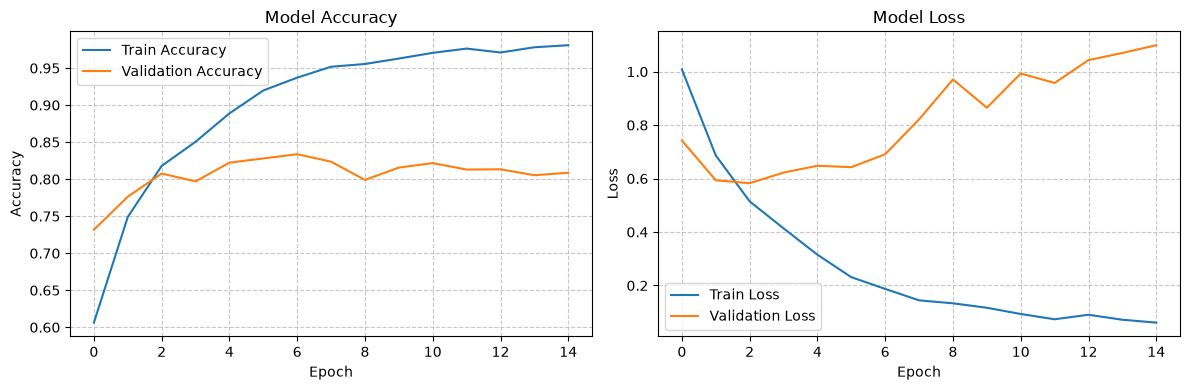

=== Classification Report ===
              precision    recall  f1-score   support

   buildings       0.76      0.77      0.77       437
      forest       0.94      0.96      0.95       474
     glacier       0.78      0.79      0.79       553
    mountain       0.72      0.76      0.74       525
         sea       0.90      0.70      0.79       510
      street       0.78      0.88      0.83       501

    accuracy                           0.81      3000
   macro avg       0.81      0.81      0.81      3000
weighted avg       0.81      0.81      0.81      3000



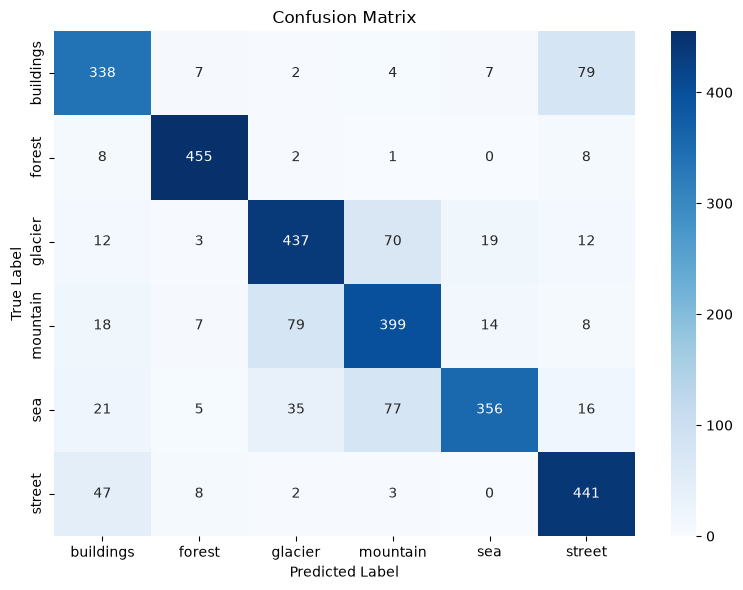

In [26]:
# 1. Plot Training History (Loss & Accuracy Curves)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# 2. Extract True Labels and Predictions from Validation Dataset
y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 3. Classification Report (Precision, Recall, F1-Score)
print("=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=classes))

# 4. Confusion Matrix Visualization
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

In [27]:
pred_dir = "seg_pred" # Adjust path if needed
class_names = sorted(os.listdir("seg_train")) # ['buildings', 'forest', ...]

# Loop through a few images in seg_pred
for img_name in os.listdir(pred_dir)[:10]: # Check first 10 images
    img_path = os.path.join(pred_dir, img_name)
    
    # Load and resize image to match model input (150x150)
    img = image.load_img(img_path, target_size=(150, 150))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) # Convert to batch of 1
    img_array /= 255.0 # Rescale
    
    # Predict
    predictions = model.predict(img_array, verbose=0)
    predicted_class_idx = np.argmax(predictions[0])
    confidence = np.max(predictions[0]) * 100
    
    predicted_class = class_names[predicted_class_idx]
    print(f"Image: {img_name} | Predicted: {predicted_class.upper()} ({confidence:.2f}%)")

Image: 63.jpg | Predicted: SEA (81.60%)
Image: 24084.jpg | Predicted: MOUNTAIN (64.93%)
Image: 13628.jpg | Predicted: GLACIER (99.86%)
Image: 3578.jpg | Predicted: FOREST (100.00%)
Image: 10321.jpg | Predicted: STREET (83.37%)
Image: 10447.jpg | Predicted: FOREST (100.00%)
Image: 12250.jpg | Predicted: GLACIER (100.00%)
Image: 1409.jpg | Predicted: FOREST (100.00%)
Image: 23099.jpg | Predicted: SEA (92.69%)
Image: 9041.jpg | Predicted: SEA (95.41%)


In [28]:
# Optimize with prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)


# ==========================================
# STABLE 3-CONV / 3-DENSE CNN ARCHITECTURE
# ==========================================

improved_model = models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    
    # Optional: Embedded light augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    
    # --- Conv Block 1 ---
    layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    
    # --- Conv Block 2 ---
    layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    
    # --- Conv Block 3 ---
    layers.Conv2D(128, kernel_size=(3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    
    layers.Flatten(),
    
    # --- Dense Layers ---
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    
    # Output Layer (6 classes)
    layers.Dense(6, activation='softmax')
])

# Use standard, reliable Adam learning rate (0.001)
improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), 
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

improved_model.summary()

# ==========================================
# TRAINING WITH CALLBACKS
# ==========================================
callbacks_list = [
    callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
]

epochs = 30  
history_improved = improved_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=callbacks_list
)

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_4 (RandomFlip)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_4               │ (None, 150, 150, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 512)            │    21,234,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,460,294 (81.86 MB)

 Trainable params: 21,460,294 (81.86 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


439/439 ━━━━━━━━━━━━━━━━━━━━ 181s 409ms/step - accuracy: 0.5635 - loss: 1.0983 - val_accuracy: 0.6660 - val_loss: 0.8228 - learning_rate: 0.0010
Epoch 2/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 176s 401ms/step - accuracy: 0.6932 - loss: 0.8166 - val_accuracy: 0.7677 - val_loss: 0.6227 - learning_rate: 0.0010
Epoch 3/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 174s 396ms/step - accuracy: 0.7498 - loss: 0.6895 - val_accuracy: 0.8173 - val_loss: 0.5199 - learning_rate: 0.0010
Epoch 4/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 172s 391ms/step - accuracy: 0.7849 - loss: 0.5961 - val_accuracy: 0.8017 - val_loss: 0.5588 - learning_rate: 0.0010
Epoch 5/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 173s 393ms/step - accuracy: 0.7975 - loss: 0.5645 - val_accuracy: 0.8097 - val_loss: 0.5248 - learning_rate: 0.0010
Epoch 6/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 171s 389ms/step - accuracy: 0.8310 - loss: 0.4731 - val_accuracy: 0.8567 - val_loss: 0.4230 - learning_rate: 5.0000e-04
Epoch 7/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 172s 393ms/step - accuracy: 0.8

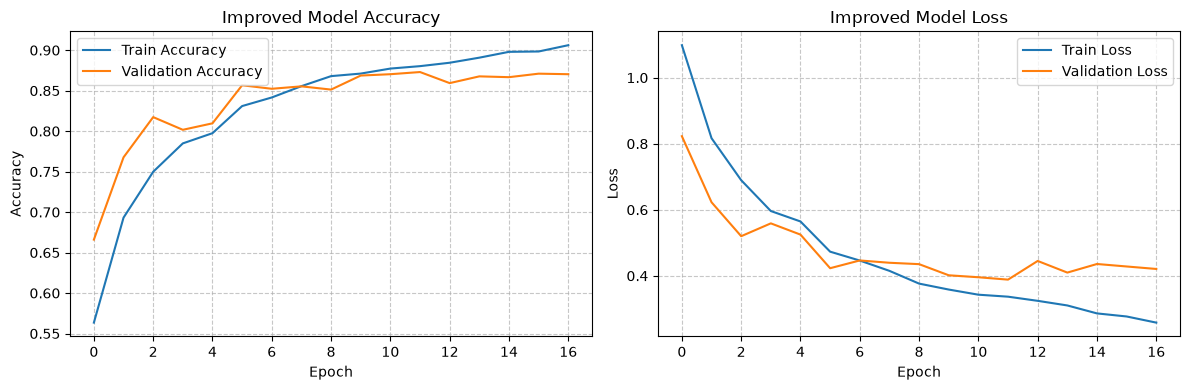

=== Improved Model Classification Report ===
              precision    recall  f1-score   support

   buildings       0.85      0.87      0.86       437
      forest       0.96      0.97      0.97       474
     glacier       0.87      0.80      0.83       553
    mountain       0.80      0.83      0.82       525
         sea       0.88      0.88      0.88       510
      street       0.88      0.89      0.89       501

    accuracy                           0.87      3000
   macro avg       0.87      0.88      0.87      3000
weighted avg       0.87      0.87      0.87      3000



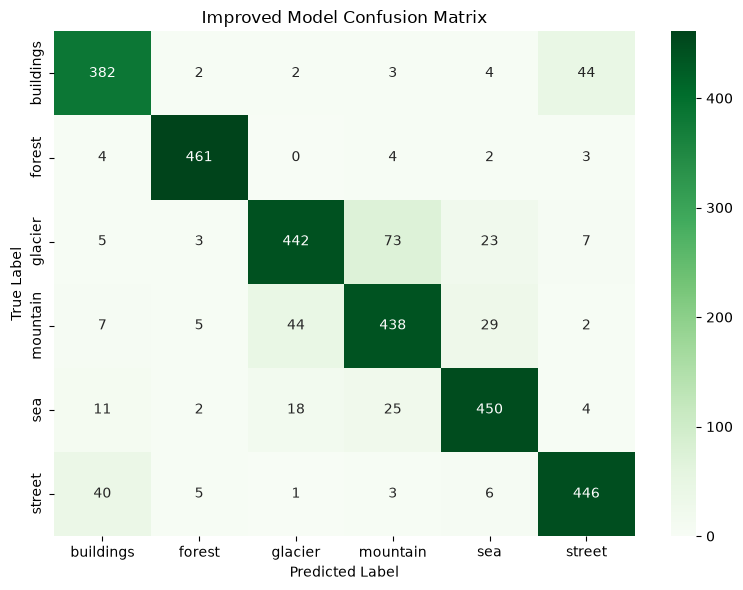

In [29]:
# ==========================================
# EVALUATION METRICS FOR IMPROVED MODEL
# ==========================================

# 1. Plot Training History (Loss & Accuracy Curves)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_improved.history['accuracy'], label='Train Accuracy')
plt.plot(history_improved.history['val_accuracy'], label='Validation Accuracy')
plt.title('Improved Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.subplot(1, 2, 2)
plt.plot(history_improved.history['loss'], label='Train Loss')
plt.plot(history_improved.history['val_loss'], label='Validation Loss')
plt.title('Improved Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# 2. Extract True Labels and Predictions from Validation Dataset
y_true_imp = []
y_pred_imp = []

for images, labels in val_ds:
    preds = improved_model.predict(images, verbose=0)
    y_true_imp.extend(np.argmax(labels.numpy(), axis=1))
    y_pred_imp.extend(np.argmax(preds, axis=1))

y_true_imp = np.array(y_true_imp)
y_pred_imp = np.array(y_pred_imp)

# 3. Classification Report (Precision, Recall, F1-Score)
print("=== Improved Model Classification Report ===")
print(classification_report(y_true_imp, y_pred_imp, target_names=classes))

# 4. Confusion Matrix Visualization
cm_imp = confusion_matrix(y_true_imp, y_pred_imp)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_imp, annot=True, fmt='d', cmap='Greens', 
            xticklabels=classes, yticklabels=classes)
plt.title('Improved Model Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()